# Telecom Churn Prediction and Profit-Based Retention

Final assignment for the GCI World 2026 course (Matsuo-Iwasawa Lab, University of Tokyo).
This is the analysis as submitted (version 1). `02_improved_pipeline.ipynb` fixes its weak points.

**Task:** a telecom company ("Company A") gave us data on about 100,000 customers. We had to find a business
problem in the data, build at least one ML model, and turn the results into a business proposal with numbers.

**What this notebook does:**
1. Loads and merges the two data files (customer info + usage history).
2. Looks at the data (missing values, churn by tenure, churn by device age).
3. Cleans the data and adds two trend features.
4. Trains an XGBoost model to predict churn.
5. Picks the decision threshold that gives the highest expected profit instead of using 0.5.
6. Uses SHAP to see which features drive churn, overall and for one high-risk customer.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")   # hides library warnings (e.g. a tqdm notice printed by shap)

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

pd.set_option("display.max_columns", 120)

import sklearn, xgboost
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | "
      f"xgboost {xgboost.__version__} | shap {shap.__version__}")

pandas 2.2.2 | numpy 2.0.2 | scikit-learn 1.6.1 | xgboost 3.0.5 | shap 0.48.0


Paths. The notebook expects the data in `data/telecom/` at the project root (see `data/README.md`).
All figures are saved to `outputs/figures/`.

On Google Colab: upload `Client.csv` and `Record.csv` and change `DATA_DIR` to the folder that has them.

In [2]:
# works when the notebook is run from the notebooks/ folder or from the project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = PROJECT_ROOT / "data" / "telecom"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

client_path = DATA_DIR / "Client.csv"
record_path = DATA_DIR / "Record.csv"

for p in (client_path, record_path):
    print(f"{'OK     ' if p.exists() else 'MISSING'} {p.relative_to(PROJECT_ROOT)}")

OK      data/telecom/Client.csv
OK      data/telecom/Record.csv


## 2. Load and merge the data

- `Client.csv`: one row per customer with account, handset and household info (50 columns).
- `Record.csv`: one row per customer with average monthly usage, billing, call quality, tenure (`months`)
  and the target `churn` (51 columns).

Both files have one row per customer, so they are joined 1:1 on `Customer_ID`.

In [3]:
def load_and_merge_data(client_path, record_path) -> pd.DataFrame:
    print("Loading data")
    try:
        client_df = pd.read_csv(client_path)
        record_df = pd.read_csv(record_path)
    except FileNotFoundError as e:
        print(f"ERROR: {e}")
        return None

    print(f"Client rows: {len(client_df):,}   columns: {client_df.shape[1]}")
    print(f"Record rows: {len(record_df):,}   columns: {record_df.shape[1]}")

    df = pd.merge(client_df, record_df, on="Customer_ID", how="inner")
    print(f"Merged rows: {len(df):,}   columns: {df.shape[1]}")

    # Churn is about 50% here, much higher than the few percent per month seen in real telecom data.
    # So the dataset looks balanced on purpose. Money numbers based on it should be scaled
    # to the real churn rate before using them for a real company.
    churn_rate = df["churn"].mean()
    print(f"\nChurn rate in this dataset: {churn_rate:.2%}")
    print("(Classes are balanced, so no oversampling like SMOTE is used.)")
    return df

In [4]:
df = load_and_merge_data(client_path, record_path)
df.head()

Loading data


Client rows: 100,000   columns: 50
Record rows: 100,000   columns: 51
Merged rows: 100,000   columns: 100

Churn rate in this dataset: 49.56%
(Classes are balanced, so no oversampling like SMOTE is used.)


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,Customer_ID,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0,1000001,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0,1000002,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0,1000003,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0,1000004,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0,1000005,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57


## 3. Exploratory data analysis

### 3.1 Missing values

Many columns have missing values. Columns that are missing in exactly the same number of rows most likely
come from the same source system (for example one household data vendor). The source names in the legend
are my guesses based on the column meanings; the dataset does not say where each column comes from.

This matters for cleaning: these values are missing for a reason, so for some columns "missing" is kept
as its own category instead of being filled with the most common value.

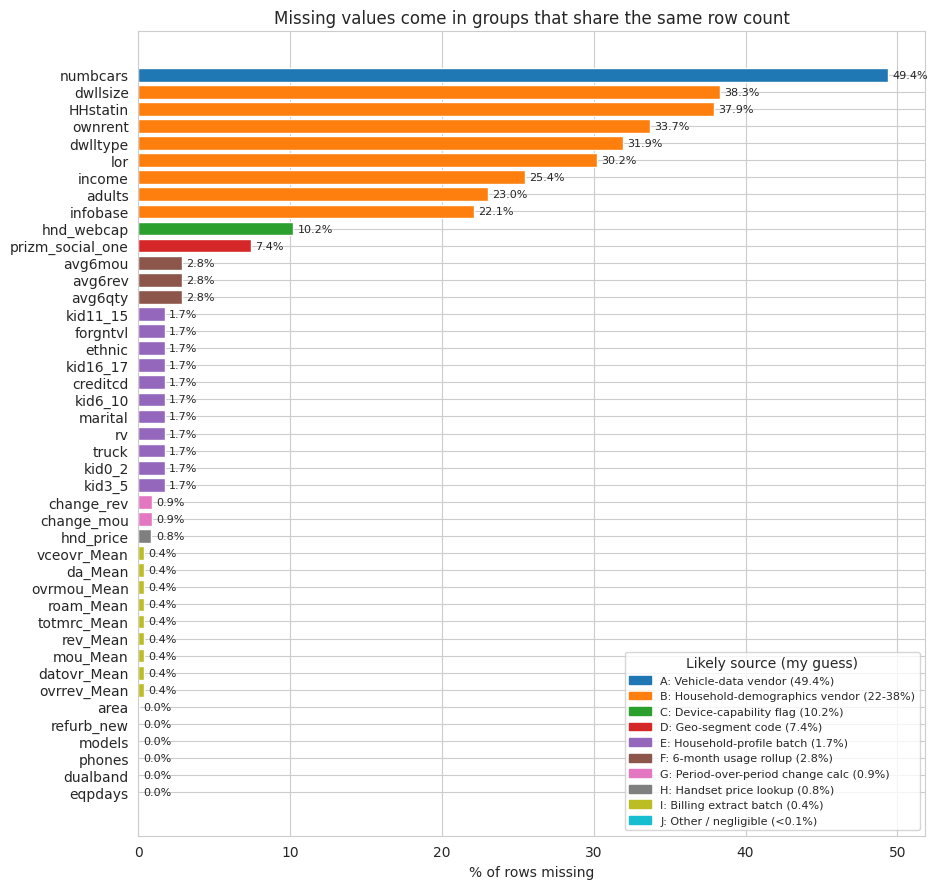

49366     1
38308     1
37923     1
33706     1
31909     1
30190     1
25436     1
23019     1
22079     1
10189     1
7388      1
2839      3
1732     11
891       2
847       1
357       9
40        1
1         5
Name: columns with this missing count, dtype: int64


In [5]:
# my guess of the source system for each group of columns (based on equal missing counts)
MISSING_SOURCE_GROUPS = {
    "A: Vehicle-data vendor": ["numbcars"],
    "B: Household-demographics vendor": ["dwllsize", "HHstatin", "ownrent", "dwlltype", "lor",
                                         "income", "adults", "infobase"],
    "C: Device-capability flag": ["hnd_webcap"],
    "D: Geo-segment code": ["prizm_social_one"],
    "E: Household-profile batch": ["kid0_2", "kid3_5", "kid6_10", "kid11_15", "kid16_17", "forgntvl",
                                   "ethnic", "creditcd", "marital", "rv", "truck"],
    "F: 6-month usage rollup": ["avg6mou", "avg6rev", "avg6qty"],
    "G: Period-over-period change calc": ["change_mou", "change_rev"],
    "H: Handset price lookup": ["hnd_price"],
    "I: Billing extract batch": ["rev_Mean", "mou_Mean", "totmrc_Mean", "da_Mean", "ovrmou_Mean",
                                 "ovrrev_Mean", "vceovr_Mean", "datovr_Mean", "roam_Mean"],
}


def plot_missingness(df):
    missing = df.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    pct = missing / len(df) * 100

    col_to_group = {c: g for g, cols in MISSING_SOURCE_GROUPS.items() for c in cols}
    other = "J: Other / negligible (<0.1%)"
    groups = list(MISSING_SOURCE_GROUPS) + [other]
    palette = dict(zip(groups, sns.color_palette("tab10", len(groups))))
    colors = [palette[col_to_group.get(c, other)] for c in pct.index]

    with sns.axes_style("whitegrid"):
        plt.figure(figsize=(9.5, 9))
        plt.barh(pct.index[::-1], pct.values[::-1], color=colors[::-1])
        for i, v in enumerate(pct.values[::-1]):
            plt.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=8)

        # legend label shows the share of missing rows in each group
        handles = []
        for g in groups:
            cols = [c for c in pct.index if col_to_group.get(c, other) == g]
            if not cols:
                continue
            lo, hi = pct[cols].min(), pct[cols].max()
            share = f"{lo:.1f}%" if hi - lo < 0.05 else f"{lo:.0f}-{hi:.0f}%"
            label = g if g == other else f"{g} ({share})"
            handles.append(plt.Rectangle((0, 0), 1, 1, color=palette[g], label=label))
        plt.legend(handles=handles, title="Likely source (my guess)", loc="lower right", fontsize=8)

        plt.xlabel("% of rows missing")
        plt.title("Missing values come in groups that share the same row count")
        plt.tight_layout()
        plt.savefig(FIG_DIR / "missingness_by_source.png", dpi=150)
        plt.show()
    return missing


missing_counts = plot_missingness(df)
print(missing_counts.groupby(missing_counts).size().sort_index(ascending=False).rename("columns with this missing count"))

### 3.2 Churn rate by tenure

Churn is highest for customers who have been with the company for 13-18 months and lowest for the longest
customers. One possible reason is customers leaving when a 12-24 month contract or handset deal ends,
but the data has no contract field, so this is only a guess.

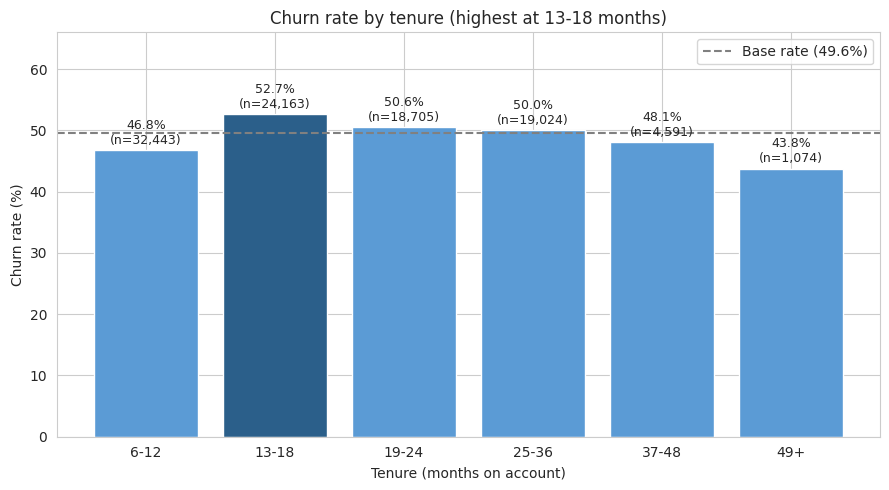

,mean,size
months,,
6-12,0.468,32443
13-18,0.527,24163
19-24,0.506,18705
25-36,0.500,19024
37-48,0.481,4591
49+,0.438,1074


In [6]:
def plot_churn_by_tenure(df):
    bins = [0, 12, 18, 24, 36, 48, np.inf]
    labels = ["6-12", "13-18", "19-24", "25-36", "37-48", "49+"]   # minimum tenure in the data is 6 months
    tenure_group = pd.cut(df["months"], bins=bins, labels=labels)
    stats = df.groupby(tenure_group, observed=True)["churn"].agg(["mean", "size"])
    base_rate = df["churn"].mean()

    colors = ["#2b5f8a" if g == stats["mean"].idxmax() else "#5b9bd5" for g in stats.index]
    with sns.axes_style("whitegrid"):
        plt.figure(figsize=(9, 5))
        bars = plt.bar(stats.index.astype(str), stats["mean"] * 100, color=colors)
        for bar, (rate, n) in zip(bars, stats.values):
            plt.text(bar.get_x() + bar.get_width() / 2, rate * 100 + 1, f"{rate:.1%}\n(n={int(n):,})",
                     ha="center", fontsize=9)
        plt.axhline(base_rate * 100, color="grey", linestyle="--", label=f"Base rate ({base_rate:.1%})")
        plt.ylim(0, 66)
        plt.xlabel("Tenure (months on account)")
        plt.ylabel("Churn rate (%)")
        plt.title(f"Churn rate by tenure (highest at {stats['mean'].idxmax()} months)")
        plt.legend()
        plt.tight_layout()
        plt.savefig(FIG_DIR / "churn_rate_by_tenure.png", dpi=150)
        plt.show()
    return stats


plot_churn_by_tenure(df).round(3)

### 3.3 Churn rate by device age

`eqpdays` is the number of days since the customer's current phone was bought. Churn goes up steadily with
device age, from about 40% for phones under 90 days old to about 60% for phones older than 3 years.
133 rows have a negative `eqpdays`, which is not possible, so they are left out of this chart only.

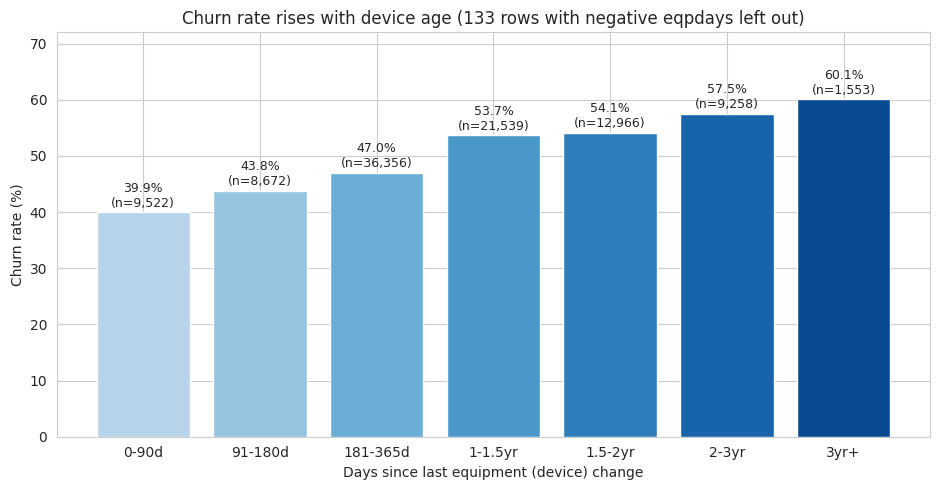

,mean,size
eqpdays,,
0-90d,0.399,9522
91-180d,0.438,8672
181-365d,0.470,36356
1-1.5yr,0.537,21539
1.5-2yr,0.541,12966
2-3yr,0.575,9258
3yr+,0.601,1553


In [7]:
def plot_churn_by_device_age(df):
    valid = df[df["eqpdays"] >= 0]
    n_negative = (df["eqpdays"] < 0).sum()

    bins = [0, 90, 180, 365, 545, 730, 1095, np.inf]
    labels = ["0-90d", "91-180d", "181-365d", "1-1.5yr", "1.5-2yr", "2-3yr", "3yr+"]
    age_group = pd.cut(valid["eqpdays"], bins=bins, labels=labels, include_lowest=True)
    stats = valid.groupby(age_group, observed=True)["churn"].agg(["mean", "size"])

    with sns.axes_style("whitegrid"):
        plt.figure(figsize=(9.5, 5))
        bars = plt.bar(stats.index.astype(str), stats["mean"] * 100,
                       color=sns.color_palette("Blues", len(stats) + 2)[2:])
        for bar, (rate, n) in zip(bars, stats.values):
            plt.text(bar.get_x() + bar.get_width() / 2, rate * 100 + 1, f"{rate:.1%}\n(n={int(n):,})",
                     ha="center", fontsize=9)
        plt.ylim(0, 72)
        plt.xlabel("Days since last equipment (device) change")
        plt.ylabel("Churn rate (%)")
        plt.title(f"Churn rate rises with device age ({n_negative} rows with negative eqpdays left out)")
        plt.tight_layout()
        plt.savefig(FIG_DIR / "churn_rate_by_device_age.png", dpi=150)
        plt.show()
    return stats


plot_churn_by_device_age(df).round(3)

## 4. Feature engineering and preprocessing

**New features (usage trend):**
- `usage_momentum_ratio = avg3mou / avg6mou`: recent 3-month usage divided by 6-month usage.
  A value below 1 means the customer is using the phone less than before.
- `revenue_momentum_ratio = avg3rev / avg6rev`: the same idea for revenue.
- A small `eps = 1e-5` is added to the bottom so customers with zero 6-month usage do not cause a divide-by-zero.

**Missing values:**
- `change_mou`, `change_rev`: missing when there is no earlier period to compare with, so they are set to 0 (no change).
- `avg6mou`, `avg6qty`, `avg6rev`: for accounts younger than 6 months the 3-month average is used instead.
  Anything still missing gets the column median.
- `prizm_social_one`: missing is kept as its own category `"Missing"`, because a failed match with the
  outside data source can itself carry information.
- `hnd_webcap`: missing becomes `"Unknown"`.
- All other numeric columns get the median, all other text columns get `"Unknown"`.

**Other steps:** `Customer_ID` is dropped (it is only an ID), and text columns are label encoded
(XGBoost needs numbers; tree models do not need one-hot encoding).

In [8]:
def preprocess_data(df: pd.DataFrame) -> pd.DataFrame:
    print("Pre-processing")
    eps = 1e-5
    df = df.copy()

    # trend features: recent 3-month average vs 6-month average
    df["usage_momentum_ratio"] = df["avg3mou"] / (df["avg6mou"] + eps)
    df["revenue_momentum_ratio"] = df["avg3rev"] / (df["avg6rev"] + eps)

    df = df.drop(columns=["Customer_ID"], errors="ignore")

    # (a) no earlier period to compare with -> treat as "no change"
    for col in ["change_mou", "change_rev"]:
        df[col] = df[col].fillna(0.0)

    # (b) 6-month averages: accounts younger than 6 months use the 3-month average
    for avg6, avg3 in [("avg6mou", "avg3mou"), ("avg6qty", "avg3qty"), ("avg6rev", "avg3rev")]:
        mask_missing = df[avg6].isna()
        df.loc[mask_missing & (df["months"] < 6), avg6] = df.loc[mask_missing & (df["months"] < 6), avg3]
        df[avg6] = df[avg6].fillna(df[avg6].median())   # anything still missing -> median
        print(f"  {avg6}: conditional imputation applied")

    # (c) failed match with the outside data source is kept as its own group
    df["prizm_social_one"] = df["prizm_social_one"].fillna("Missing")
    print("  prizm_social_one: NaN -> 'Missing' (own category)")

    # (d) unknown handset web capability
    df["hnd_webcap"] = df["hnd_webcap"].fillna("Unknown")
    print("  hnd_webcap: NaN -> 'Unknown'")

    # all other numeric columns -> median
    num_cols = df.select_dtypes(include=[np.number]).columns
    for col in num_cols:
        if df[col].isna().sum() > 0:
            df[col] = df[col].fillna(df[col].median())

    # all other text columns -> 'Unknown'
    cat_cols = df.select_dtypes(include=["object", "string"]).columns
    for col in cat_cols:
        if df[col].isna().sum() > 0:
            df[col] = df[col].fillna("Unknown")

    # label encode the text columns
    cat_cols_final = df.select_dtypes(include=["object", "string"]).columns.tolist()
    for col in cat_cols_final:
        df[col] = LabelEncoder().fit_transform(df[col].astype(str))

    print(f"\nEncoded {len(cat_cols_final)} categorical columns.")
    print(f"Final feature count (incl. target): {df.shape[1]}")
    return df

In [9]:
df_processed = preprocess_data(df)

Pre-processing
  avg6mou: conditional imputation applied
  avg6qty: conditional imputation applied
  avg6rev: conditional imputation applied
  prizm_social_one: NaN -> 'Missing' (own category)
  hnd_webcap: NaN -> 'Unknown'



Encoded 21 categorical columns.
Final feature count (incl. target): 101


### 4.1 Why the trend feature helps

Raw usage level (`mou_Mean`) only says churners use a bit less. The trend feature shows something
different: the median churner's usage is flat or going down (ratio about 1.00), while the median retained
customer is still slightly growing (ratio about 1.02). The difference is small, but it describes a change
in behaviour and not just a lower level. This uses the raw data, before any filling of missing values.

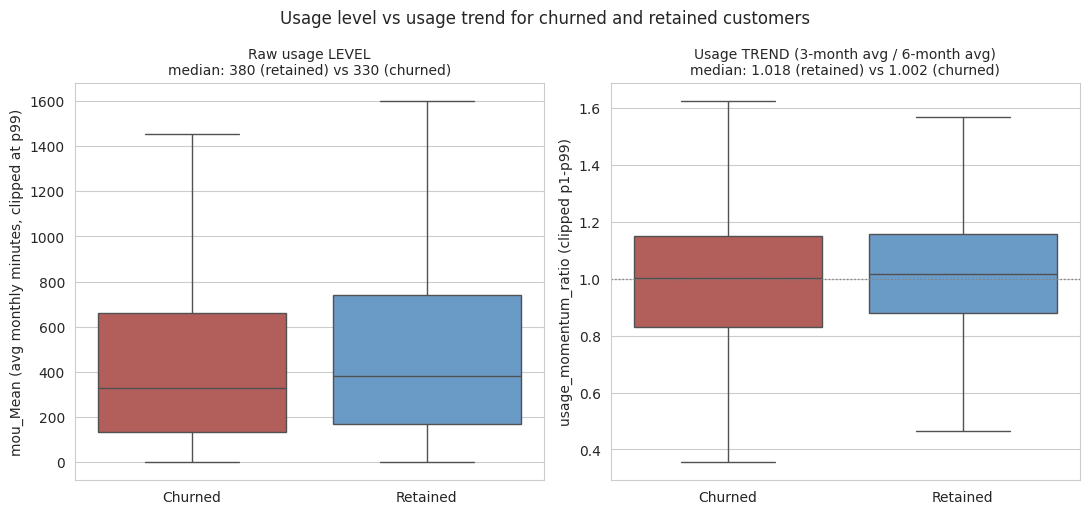

,mou_Mean,usage_momentum_ratio
status,,
Churned,329.75,1.001980
Retained,380.50,1.018349


In [10]:
def plot_usage_level_vs_trend(df, eps=1e-5):
    plot_df = pd.DataFrame({
        "mou_Mean": df["mou_Mean"],
        "usage_momentum_ratio": df["avg3mou"] / (df["avg6mou"] + eps),
        "status": df["churn"].map({1: "Churned", 0: "Retained"}),
    })
    medians = plot_df.groupby("status")[["mou_Mean", "usage_momentum_ratio"]].median()

    # clip extreme values so the boxes are readable
    plot_df["mou_Mean"] = plot_df["mou_Mean"].clip(upper=plot_df["mou_Mean"].quantile(0.99))
    ratio = plot_df["usage_momentum_ratio"]
    plot_df["usage_momentum_ratio"] = ratio.clip(ratio.quantile(0.01), ratio.quantile(0.99))

    palette = {"Churned": "#c0504d", "Retained": "#5b9bd5"}
    order = ["Churned", "Retained"]
    with sns.axes_style("whitegrid"):
        fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))

        sns.boxplot(data=plot_df, x="status", y="mou_Mean", order=order, palette=palette,
                    showfliers=False, ax=axes[0])
        axes[0].set_title("Raw usage LEVEL\n"
                          f"median: {medians.loc['Retained', 'mou_Mean']:.0f} (retained) vs "
                          f"{medians.loc['Churned', 'mou_Mean']:.0f} (churned)", fontsize=10)
        axes[0].set_ylabel("mou_Mean (avg monthly minutes, clipped at p99)")

        sns.boxplot(data=plot_df, x="status", y="usage_momentum_ratio", order=order, palette=palette,
                    showfliers=False, ax=axes[1])
        axes[1].axhline(1.0, color="grey", linestyle=":", linewidth=1)
        axes[1].set_title("Usage TREND (3-month avg / 6-month avg)\n"
                          f"median: {medians.loc['Retained', 'usage_momentum_ratio']:.3f} (retained) vs "
                          f"{medians.loc['Churned', 'usage_momentum_ratio']:.3f} (churned)", fontsize=10)
        axes[1].set_ylabel("usage_momentum_ratio (clipped p1-p99)")

        for ax in axes:
            ax.set_xlabel("")
        fig.suptitle("Usage level vs usage trend for churned and retained customers")
        plt.tight_layout()
        plt.savefig(FIG_DIR / "usage_level_vs_trend_by_churn.png", dpi=150)
        plt.show()
    return medians


plot_usage_level_vs_trend(df)

## 5. Feature selection and train/test split

- `VarianceThreshold(0.0)` removes columns that have the same value in every row (none are found here).
- A stratified 80/20 split keeps the same churn share in train and test.
- Lasso-based feature selection was planned but not used, because it was slow on 100k rows and XGBoost
  can deal with many features.

In [11]:
def select_features_and_split(df: pd.DataFrame):
    print("Feature selection & splitting")
    target_col = "churn"
    y = df[target_col]
    X = df.drop(columns=[target_col])
    print(f"Target: {target_col}  | class balance: {y.value_counts().to_dict()}")

    # drop constant columns
    vt = VarianceThreshold(threshold=0.0)
    vt.fit(X)
    kept_mask = vt.get_support()
    removed = X.columns[~kept_mask].tolist()
    X = X.loc[:, kept_mask]
    print(f"  VarianceThreshold: removed {len(removed)} zero-variance feature(s).")
    if removed:
        print(f"  Removed: {removed}")
    print(f"  Features retained: {X.shape[1]}")

    # stratified 80/20 split, fixed seed so the split is the same every run
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    print(f"  Train: {len(X_train):,}   Test: {len(X_test):,}")

    # feature names are needed later for SHAP
    return X_train, X_test, y_train, y_test, list(X.columns)

In [12]:
X_train, X_test, y_train, y_test, feature_names = select_features_and_split(df_processed)

Feature selection & splitting
Target: churn  | class balance: {0: 50438, 1: 49562}


  VarianceThreshold: removed 0 zero-variance feature(s).
  Features retained: 100
  Train: 80,000   Test: 20,000


## 6. Model: XGBoost

XGBoost is a good fit for this kind of table data: it handles mixed feature types and non-linear effects,
and it works with SHAP for explanations. The main metric is **ROC-AUC**, because it checks how well the
model ranks customers by churn risk, without picking a threshold. Accuracy and the classification report
use the default 0.5 threshold.

In [13]:
def train_and_evaluate(X_train, X_test, y_train, y_test):
    print("Training XGBoost")
    model = XGBClassifier(
        n_estimators=350,        # number of trees
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,           # each tree sees 80% of the rows
        colsample_bytree=0.8,    # and 80% of the columns
        objective="binary:logistic",
        eval_metric="auc",
        random_state=42,
        n_jobs=-1,
    )
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]   # probability of churn

    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    print("MODEL PERFORMANCE SUMMARY")
    print("Model name     : XGBoost (XGBClassifier)")
    print("Primary metric : ROC-AUC")
    print(f"ROC-AUC score  : {auc:.4f}")
    print(f"Accuracy       : {acc:.4f}")

    print("\nDetailed Classification Report:")
    print(classification_report(y_test, y_pred, target_names=["Retained (0)", "Churned (1)"]))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Retained (0)", "Churned (1)"],
                yticklabels=["Retained (0)", "Churned (1)"])
    plt.title("Confusion Matrix: XGBoost Churn Prediction")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=150)
    plt.show()

    return model, y_prob

Training XGBoost


MODEL PERFORMANCE SUMMARY
Model name     : XGBoost (XGBClassifier)
Primary metric : ROC-AUC
ROC-AUC score  : 0.6952
Accuracy       : 0.6394

Detailed Classification Report:
              precision    recall  f1-score   support

Retained (0)       0.65      0.63      0.64     10088
 Churned (1)       0.63      0.65      0.64      9912

    accuracy                           0.64     20000
   macro avg       0.64      0.64      0.64     20000
weighted avg       0.64      0.64      0.64     20000



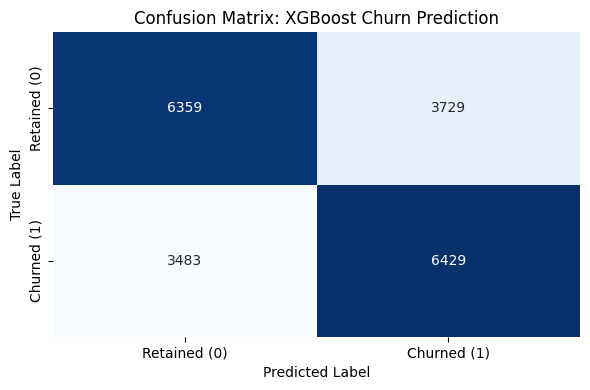

In [14]:
model, y_prob = train_and_evaluate(X_train, X_test, y_train, y_test)

**How well does the score rank customers?** The test customers are split into 10 equal groups by predicted
churn probability (group 1 = highest scores). If the ranking is useful, the real churn rate should fall
from group 1 to group 10.

In [15]:
ranking = pd.DataFrame({"churn_prob": y_prob, "churned": y_test.values})
# rank first so that ties do not break qcut; group 1 = highest predicted risk
ranking["risk_group"] = 10 - pd.qcut(ranking["churn_prob"].rank(method="first"), 10, labels=False)
ranking.groupby("risk_group")["churned"].agg(churn_rate="mean", customers="size").round(3)

,churn_rate,customers
risk_group,,
1,0.786,2000
2,0.696,2000
3,0.610,2000
4,0.558,2000
5,0.525,2000
6,0.457,2000
7,0.436,2000
8,0.390,2000
9,0.305,2000


The 10% of customers with the highest scores churn at about 79%, the lowest 10% at about 19%
(overall rate 49.6%). So the model is far from perfect, but it ranks customers well enough to decide who
to contact first when the budget is limited.

## 7. Profit-based decision threshold (e-Profits)

The 0.5 threshold treats both kinds of mistakes as equally bad, but they do not cost the same.
Each cell of the confusion matrix gets a money value:

| Outcome | Meaning | Value |
|---|---|---|
| True positive | churner gets an offer and stays | LTV - offer cost = 58.72 x 12 - 35 |
| False positive | loyal customer gets an offer anyway | -35 (wasted offer) |
| False negative | churner is missed and leaves | -400 (cost to win a new customer) |
| True negative | loyal customer, no action | 0 |

- ARPU = $58.72 per month is the mean of `rev_Mean` in this data. LTV uses a 12-month lifetime.
- The offer cost ($35) and acquisition cost ($400) are assumptions, not values from the data.

The function tries 200 thresholds between 0.01 and 0.99 and keeps the one with the highest total profit
on the test set.

In [16]:
def optimise_threshold_eprofits(y_test, y_prob,
                                arpu_monthly: float = 58.72,     # mean of rev_Mean in this data
                                lifetime_months: int = 12,       # assumed customer lifetime
                                cost_retention: float = 35.0,    # assumed cost of one retention offer
                                cost_acquisition: float = 400.0  # assumed cost to acquire a new customer
                                ):
    """Finds the decision threshold with the highest expected profit on the test set.

    TP: churner saved          -> ltv - cost_retention
    FP: offer sent to a stayer -> -cost_retention
    FN: churner missed         -> -cost_acquisition
    TN: no action              -> 0
    """
    print("e-Profits threshold optimisation")
    ltv = arpu_monthly * lifetime_months
    thresholds = np.linspace(0.01, 0.99, 200)
    profits = []

    for thr in thresholds:
        y_hat = (y_prob >= thr).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, y_hat).ravel()
        profit = (
            tp * (ltv - cost_retention)   # saved churner
            + fp * (-cost_retention)      # wasted offer
            + fn * (-cost_acquisition)    # lost customer
            + tn * 0.0                    # loyal customer, no cost
        )
        profits.append(profit)

    profits = np.array(profits)
    best_idx = np.argmax(profits)
    best_thr = thresholds[best_idx]
    best_profit = profits[best_idx]

    print(f"  Optimal threshold  : {best_thr:.3f}  (default 0.5)")
    print(f"  Max expected profit: ${best_profit:,.0f}  (test set, {len(y_test):,} customers)")

    plt.figure(figsize=(8, 4))
    plt.plot(thresholds, profits / 1e6, color="steelblue", lw=2)
    plt.axvline(best_thr, color="tomato", linestyle="--", label=f"Optimal threshold = {best_thr:.3f}")
    plt.axvline(0.5, color="grey", linestyle=":", label="Default threshold = 0.50")
    plt.xlabel("Decision Threshold")
    plt.ylabel("Expected Profit (USD Millions)")
    plt.title("e-Profits Threshold Optimisation\n"
              f"(ARPU=${arpu_monthly:.2f}/mo, CRC=${cost_retention}, CAC=${cost_acquisition})")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIG_DIR / "eprofits_threshold.png", dpi=150)
    plt.show()

    return best_thr

e-Profits threshold optimisation


  Optimal threshold  : 0.099  (default 0.5)
  Max expected profit: $6,286,002  (test set, 20,000 customers)


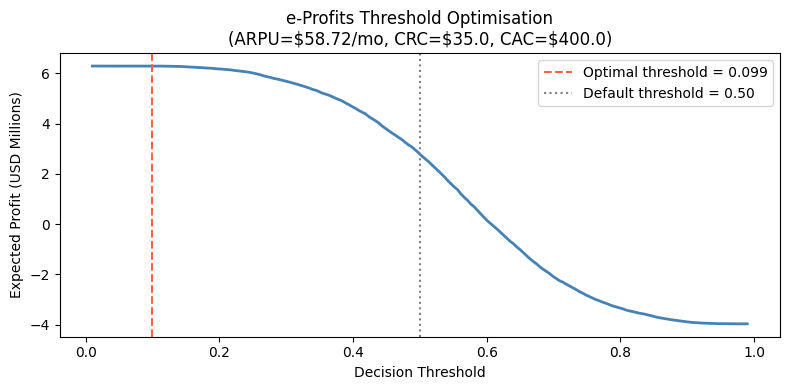

In [17]:
optimal_threshold = optimise_threshold_eprofits(y_test, y_prob)

**Sanity check.** Because a missed churner (-$400) costs much more than a wasted offer (-$35), the best
threshold ends up very low. The cell below checks how many test customers get an offer at this threshold
and compares the profit with two simple rules: offer everyone, and use the default 0.5 threshold.

In [18]:
def profit_at(threshold, arpu_monthly=58.72, lifetime_months=12, cost_retention=35.0, cost_acquisition=400.0):
    tn, fp, fn, tp = confusion_matrix(y_test, (y_prob >= threshold).astype(int), labels=[0, 1]).ravel()
    ltv = arpu_monthly * lifetime_months
    return tp * (ltv - cost_retention) - fp * cost_retention - fn * cost_acquisition


def money(v):
    return f"-${-v:,.0f}" if v < 0 else f"${v:,.0f}"


n_targeted = int((y_prob >= optimal_threshold).sum())
print(f"Customers who get an offer at threshold {optimal_threshold:.3f}: {n_targeted:,} of {len(y_test):,} "
      f"({n_targeted / len(y_test):.1%})")
print(f"Profit at optimal threshold     : {money(profit_at(optimal_threshold))}")
print(f"Profit if everyone gets an offer: {money(profit_at(0.0))}")
print(f"Profit at default 0.5 threshold : {money(profit_at(0.5))}")
print(f"Profit if nobody gets an offer  : {money(profit_at(1.01))}")

Customers who get an offer at threshold 0.099: 19,954 of 20,000 (99.8%)
Profit at optimal threshold     : $6,286,002
Profit if everyone gets an offer: $6,284,392
Profit at default 0.5 threshold : $2,781,401
Profit if nobody gets an offer  : -$3,964,800


With these cost numbers the "optimal" threshold sends an offer to almost every test customer, and the
profit is close to just giving everyone an offer. So the profit number mostly comes from the cost
assumptions, and the model adds little on top of a blanket campaign in this setup. The calculation also
assumes that every churner who gets an offer stays. These limits are listed in the README.

## 8. Explaining the model with SHAP

SHAP gives each feature a contribution to each prediction. It is computed on a random sample of 1,000 test
customers to keep it fast.

1. Bar chart: average impact of each feature (global importance).
2. Beeswarm: direction of the impact (high or low feature values pushing churn up or down).
3. Waterfall: why the model gave the highest churn score in the sample to one customer, with a suggested
   retention action for the top drivers.

In [19]:
def generate_business_insights(model, X_test, feature_names):
    print("SHAP explainability")
    explainer = shap.TreeExplainer(model)
    n_sample = min(1000, len(X_test))
    X_sample = X_test.sample(n=n_sample, random_state=42)
    shap_values = explainer.shap_values(X_sample)

    # (a) global importance: mean |SHAP value| per feature
    shap.summary_plot(shap_values, X_sample, plot_type="bar", show=False)
    plt.title("Macro Drivers of Churn (SHAP feature importance)")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "shap_importance.png", dpi=150)
    plt.show()

    # (b) direction of impact (the plot shuffles the dots randomly, the seed keeps the picture the same)
    np.random.seed(42)
    shap.summary_plot(shap_values, X_sample, show=False)
    plt.title("Directional Impact of Features on Churn Probability")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "shap_beeswarm.png", dpi=150)
    plt.show()

    # (c) customer with the highest churn probability in the SHAP sample
    y_prob_sample = model.predict_proba(X_sample)[:, 1]
    highest_risk_idx = np.argmax(y_prob_sample)
    risk_score = y_prob_sample[highest_risk_idx]

    # top 5 SHAP drivers for this customer, mapped to a suggested action
    sv_row = shap_values[highest_risk_idx]
    top_features_sorted = np.argsort(np.abs(sv_row))[::-1][:5]

    print(f"\nHighest-risk customer in the sample (churn prob = {risk_score:.2%})")
    print("Top 5 SHAP drivers:")
    intervention_map = {
        "eqpdays": "Hardware upgrade voucher (zero-down, 24-month contract)",
        "ovrrev_Mean": "Upgrade to unlimited plan to eliminate bill shock",
        "drop_vce_Mean": "Proactive retention call with discretionary billing credit",
        "custcare_Mean": "Flag for specialist retention agent outreach",
        "change_mou": "Re-engagement offer (data bonus / loyalty reward)",
    }
    for fi in top_features_sorted:
        fname = feature_names[fi]
        hint = intervention_map.get(fname, "Review account and personalise offer")
        print(f"    [{fi:3d}] {fname:25s}  SHAP = {sv_row[fi]:+.4f}  {hint}")

    shap_exp = shap.Explanation(
        values=shap_values[highest_risk_idx],
        base_values=explainer.expected_value,
        data=X_sample.iloc[highest_risk_idx].values,
        feature_names=feature_names,
    )
    shap.waterfall_plot(shap_exp, show=False)
    plt.title(f"SHAP Waterfall: Highest-Risk Customer (churn prob = {risk_score:.2%})")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "shap_waterfall_highest_risk.png", dpi=150)
    plt.show()

    # mean |SHAP| per feature, used in the next section
    return pd.Series(np.abs(shap_values).mean(axis=0), index=feature_names).sort_values(ascending=False)

SHAP explainability


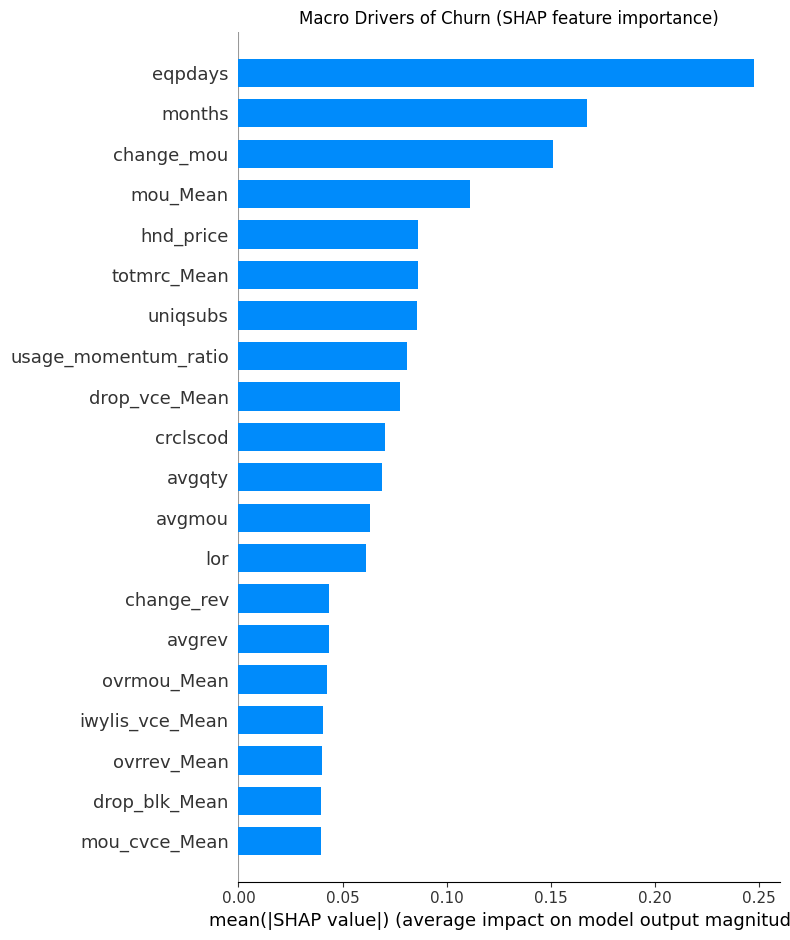

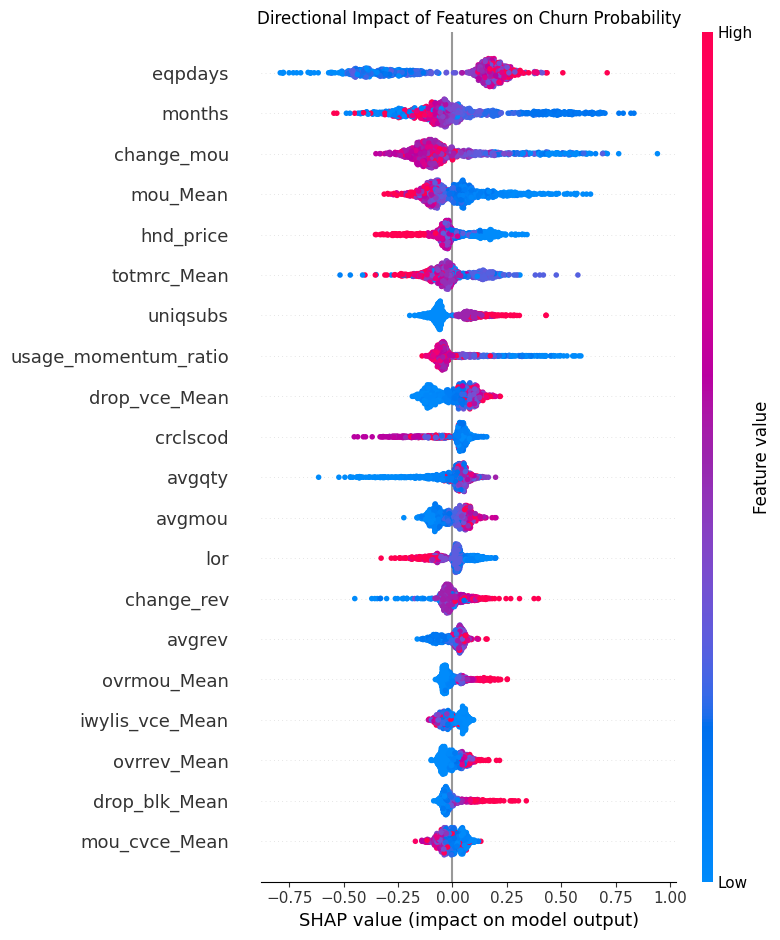


Highest-risk customer in the sample (churn prob = 92.06%)
Top 5 SHAP drivers:
    [ 50] mou_Mean                   SHAP = +0.6161  Review account and personalise offer
    [ 98] usage_momentum_ratio       SHAP = +0.4214  Review account and personalise offer
    [ 48] eqpdays                    SHAP = +0.2191  Hardware upgrade voucher (zero-down, 24-month contract)
    [ 97] months                     SHAP = +0.1895  Review account and personalise offer
    [ 24] hnd_price                  SHAP = +0.1487  Review account and personalise offer


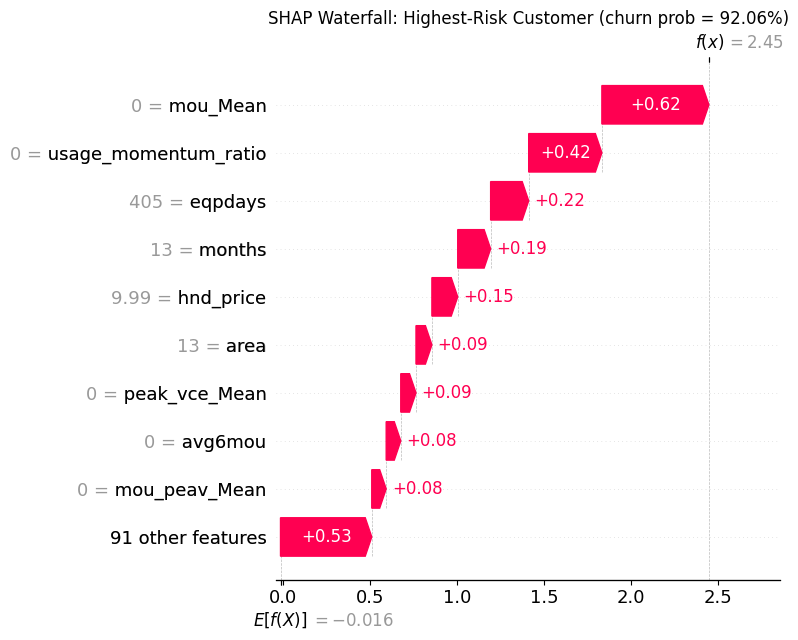

eqpdays                 0.247774
months                  0.167234
change_mou              0.151086
mou_Mean                0.111340
hnd_price               0.086461
totmrc_Mean             0.086032
uniqsubs                0.085731
usage_momentum_ratio    0.080770
drop_vce_Mean           0.077556
crclscod                0.070585
dtype: float32

In [20]:
shap_importance = generate_business_insights(model, X_test, feature_names)
shap_importance.head(10)

### 8.1 Do the top SHAP drivers correlate with churn?

Pearson correlation between churn and the 9 most important SHAP features (values clipped at the 1st and
99th percentile so a few extreme rows do not dominate). The largest correlation with churn is only about
0.1. Each feature on its own has a weak straight-line link with churn, so a simple rule based on one or two
columns would not work well. The model gets its signal from combining many features.

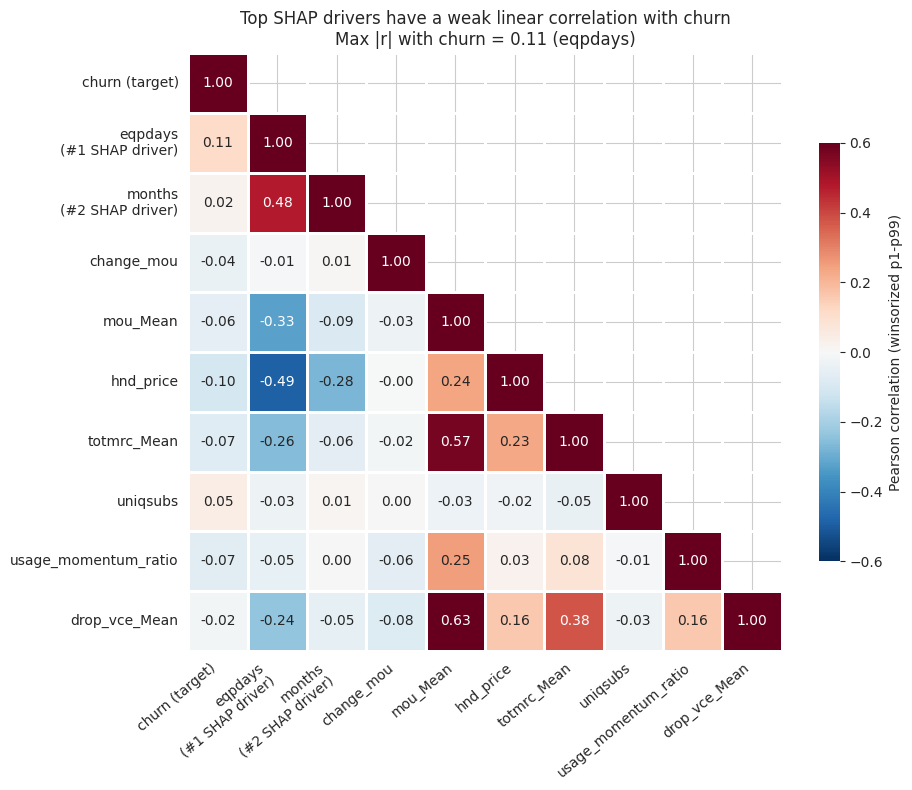

,churn,eqpdays,months,change_mou,mou_Mean,hnd_price,totmrc_Mean,uniqsubs,usage_momentum_ratio,drop_vce_Mean
churn,1.00,0.11,0.02,-0.04,-0.06,-0.10,-0.07,0.05,-0.07,-0.02
eqpdays,0.11,1.00,0.48,-0.01,-0.33,-0.49,-0.26,-0.03,-0.05,-0.24
months,0.02,0.48,1.00,0.01,-0.09,-0.28,-0.06,0.01,0.00,-0.05
change_mou,-0.04,-0.01,0.01,1.00,-0.03,-0.00,-0.02,0.00,-0.06,-0.08
mou_Mean,-0.06,-0.33,-0.09,-0.03,1.00,0.24,0.57,-0.03,0.25,0.63
hnd_price,-0.10,-0.49,-0.28,-0.00,0.24,1.00,0.23,-0.02,0.03,0.16
totmrc_Mean,-0.07,-0.26,-0.06,-0.02,0.57,0.23,1.00,-0.05,0.08,0.38
uniqsubs,0.05,-0.03,0.01,0.00,-0.03,-0.02,-0.05,1.00,-0.01,-0.03
usage_momentum_ratio,-0.07,-0.05,0.00,-0.06,0.25,0.03,0.08,-0.01,1.00,0.16
drop_vce_Mean,-0.02,-0.24,-0.05,-0.08,0.63,0.16,0.38,-0.03,0.16,1.00


In [21]:
def plot_driver_correlation(df, top_features, eps=1e-5):
    data = df.copy()
    data["usage_momentum_ratio"] = data["avg3mou"] / (data["avg6mou"] + eps)
    cols = ["churn"] + list(top_features)
    data = data[cols]
    data = data.clip(data.quantile(0.01), data.quantile(0.99), axis=1)   # winsorize p1-p99
    corr = data.corr()

    labels = ["churn (target)"] + [
        f"{f}\n(#{i + 1} SHAP driver)" if i < 2 else f for i, f in enumerate(top_features)
    ]
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    churn_corr = corr["churn"].drop("churn").abs()

    with sns.axes_style("whitegrid"):
        plt.figure(figsize=(9.5, 8))
        sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-0.6, vmax=0.6,
                    linewidths=1, linecolor="white", xticklabels=labels, yticklabels=labels,
                    cbar_kws={"label": "Pearson correlation (winsorized p1-p99)", "shrink": 0.7})
        plt.title("Top SHAP drivers have a weak linear correlation with churn\n"
                  f"Max |r| with churn = {churn_corr.max():.2f} ({churn_corr.idxmax()})")
        plt.xticks(rotation=40, ha="right")
        plt.tight_layout()
        plt.savefig(FIG_DIR / "correlation_heatmap_top_drivers.png", dpi=150)
        plt.show()
    return corr


plot_driver_correlation(df, shap_importance.index[:9]).round(2)

## 9. Results and conclusion

**Model:** XGBoost, ROC-AUC about 0.695 and accuracy about 0.64 on the 20,000-customer test set.
This is a modest score. The data does not separate churners and non-churners very clearly.

**Main churn drivers (SHAP):** device age (`eqpdays`), tenure (`months`), change in usage (`change_mou`),
usage level (`mou_Mean`), handset price, monthly plan charge, number of subscribers in the household and
the new usage trend feature.

**Business view:**
- Older devices go with higher churn, so a handset upgrade offer for customers with old phones is the
  clearest action from this analysis.
- Churn is highest around 13-18 months of tenure, which is a good time to reach out.
- With the cost assumptions used here ($35 offer, $400 acquisition cost), the profit-based threshold is very
  low and almost every customer gets an offer. A real rollout would need real campaign costs, the real
  churn rate and the real success rate of offers before trusting the profit number.

**Not done / possible next steps:** survival analysis (when a customer churns, not only if), proper
hyperparameter tuning (for example with Optuna), and fitting the imputation on the training set only.